<span style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">An Exception was encountered at '<a href="#papermill-error-cell">In [39]</a>'.</span>

# PA005: High Customer Identification (Insiders)

# 0.0. Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import regex as re

import umap.umap_ as umap

from matplotlib import pyplot as plt

from sklearn import cluster as c
from sklearn import metrics as m
from sklearn import preprocessing as pp
from sklearn import decomposition as dd
from sklearn import ensemble as en
from sklearn.manifold import TSNE
from sklearn import mixture as mx

from scipy.cluster import hierarchy as hc

from plotly import express as px


## 0.2. Load dataset

In [2]:
# load data
path = '/home/gabri/repos/pa005/projetoaluno/'
df_raw = pd.read_csv( path + 'data/raw/Ecommerce.csv', encoding='ISO-8859-1')

# drop extra column
df_raw.drop( columns=['Unnamed: 8'], axis=1, inplace = True)

#  <font color='red'> 1.0. Descrição dos Dados </font>

In [3]:
df1 = df_raw.copy()

In [4]:
df1.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,29-Nov-16,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,29-Nov-16,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,29-Nov-16,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,29-Nov-16,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,29-Nov-16,3.39,17850.0,United Kingdom


## 1.1. Rename Columns

In [5]:
cols_new = ['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country']
df1.columns = cols_new

## 1.2. Data Dimensions

In [6]:
print( 'Number of rows: {}'.format( df1.shape[0] ) )
print( 'Number of cols: {}'.format( df1.shape[1] ) )

Number of rows: 541909
Number of cols: 8


## 1.3. Data Types

In [7]:
df1.dtypes

invoice_no       object
stock_code       object
description      object
quantity          int64
invoice_date     object
unit_price      float64
customer_id     float64
country          object
dtype: object

## 1.4. Check NA

In [8]:
df1.isna().sum()

invoice_no           0
stock_code           0
description       1454
quantity             0
invoice_date         0
unit_price           0
customer_id     135080
country              0
dtype: int64

## 1.5. Replace NA

In [9]:
df_missing = df1.loc[df1['customer_id'].isna(), :]
df_not_missing = df1.loc[~df1['customer_id'].isna(), :]

In [10]:
# create reference
df_backup = pd.DataFrame( df_missing['invoice_no'].drop_duplicates() )
df_backup['customer_id'] = np.arange(19000, 19000 + len(df_backup), 1)

# merge original with reference dataframe
df1 = pd.merge(df1, df_backup, how='left', on='invoice_no')

# coalesce
df1['customer_id'] = df1['customer_id_x'].combine_first(df1['customer_id_y'])

# drop extra columns
df1 = df1.drop(columns=['customer_id_x', 'customer_id_y'], axis=1)

In [11]:
df1.isna().sum()

invoice_no         0
stock_code         0
description     1454
quantity           0
invoice_date       0
unit_price         0
country            0
customer_id        0
dtype: int64

## 1.6. Change dtypes

In [12]:
# invoice_date
df1['invoice_date'] = pd.to_datetime( df1['invoice_date'], format='%d-%b-%y' )

# customer_id
df1['customer_id'] = df1['customer_id'].astype(int)

df1.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,country,customer_id
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2016-11-29,2.55,United Kingdom,17850
1,536365,71053,WHITE METAL LANTERN,6,2016-11-29,3.39,United Kingdom,17850
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2016-11-29,2.75,United Kingdom,17850
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2016-11-29,3.39,United Kingdom,17850
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2016-11-29,3.39,United Kingdom,17850


In [13]:
df1.dtypes

invoice_no              object
stock_code              object
description             object
quantity                 int64
invoice_date    datetime64[ns]
unit_price             float64
country                 object
customer_id              int64
dtype: object

## 1.7. Descriptive Statistics

In [14]:
num_attributes = df1.select_dtypes( include=['int64', 'float64'] )
cat_attributes = df1.select_dtypes( exclude=['int64', 'float64', 'datetime64[ns]'])

### 1.7.1. Numerical Attributes

In [15]:
# Central tendency - mean, median
ct1 = pd.DataFrame( num_attributes.apply( np.mean ) ).T
ct2 = pd.DataFrame( num_attributes.apply( np.median ) ).T

# Dispersion - desvio padrão, min, max, range, std, skew, kurtosis
d1 = pd.DataFrame( num_attributes.apply( np.std ) ).T
d2 = pd.DataFrame( num_attributes.apply( np.min ) ).T
d3 = pd.DataFrame( num_attributes.apply( np.max ) ).T
d4 = pd.DataFrame( num_attributes.apply( lambda x: x.max() - x.min() ) ).T
d5 = pd.DataFrame( num_attributes.apply( lambda x: x.skew() ) ).T
d6 = pd.DataFrame( num_attributes.apply( lambda x: x.kurtosis() ) ).T

# concatenate
m1 = pd.concat( [d2, d3, d4, ct1, ct2, d1, d5, d6] ).T.reset_index()
m1.columns = ['attributes', 'min', 'max', 'range', 'mean', 'mediana', 'std', 'skew', 'kurtosis']
m1

,attributes,min,max,range,mean,mediana,std,skew,kurtosis
0,quantity,-80995.00,80995.0,161990.00,9.552250,3.00,218.080957,-0.264076,119769.160031
1,unit_price,-11062.06,38970.0,50032.06,4.611114,2.08,96.759764,186.506972,59005.719097
2,customer_id,12346.00,22709.0,10363.00,16688.840453,16249.00,2911.408666,0.487449,-0.804287


### 1.7.2. Categorical Attributes

<b>invoice_no</b>

In [16]:
# Problema: Temos invoice com letras e numeros
# df1['invoice_no'].astype( int )

# identificacao
df_letter_invoices = df1.loc[df1['invoice_no'].apply( lambda x: bool( re.search( '[^0-9]+', x) ) ), :]
df_letter_invoices.head()

print( 'Total number of invoices: {}'.format( len( df_letter_invoices )))
print( 'Total number of negative quantity: {}'.format( len( df_letter_invoices[ df_letter_invoices['quantity'] < 0 ] )))

#len( cat_attributes.loc[cat_attributes['invoice_no'].apply( lambda x: bool( re.search( '[^0-9]+', x) ) ), 'invoice_no'].drop_duplicates() )

Total number of invoices: 9291
Total number of negative quantity: 9288


<b>stock_code</b>

In [17]:
#check stock codes only characteres 
df1.loc[cat_attributes['stock_code'].apply( lambda x: bool( re.search( '^[a-zA-Z]+$', x) ) ), 'stock_code'].unique()

# Ação:
## 1. Remove stock_code in ['POST', 'D', 'M', 'PADS', 'DOT', 'CRUK']

array(['POST', 'D', 'DOT', 'M', 'S', 'AMAZONFEE', 'm', 'DCGSSBOY',
       'DCGSSGIRL', 'PADS', 'B', 'CRUK'], dtype=object)

#  <font color='red'> 2.0. Filtragem de Variáveis</font>

In [18]:
df2 = df1.copy()

In [19]:
df2.dtypes

invoice_no              object
stock_code              object
description             object
quantity                 int64
invoice_date    datetime64[ns]
unit_price             float64
country                 object
customer_id              int64
dtype: object

In [20]:
# === Numerical Attributes ======

# unit price > 0.0
df2 = df2.loc[df2['unit_price'] >= 0.04, :]

# === Categorical Attributes ===
df2 = df2[~df2['stock_code'].isin( ['POST', 'D', 'DOT', 'M', 'S', 'AMAZONFEE', 'm', 'DCGSSBOY', 'DCGSSGIRL', 'PADS', 'B', 'CRUK'] )]

# description
df2 = df2.drop( columns='description', axis=1)

# map
df2 = df2[~df2['country'].isin( ['European Community', 'Unspecified'] )]

# bad users
df2 = df2[~df2['customer_id'].isin( [16446])]

## quantity - Negative numbers means products returns
df2_returns = df2.loc[df2['quantity'] < 0, :]
df2_purchases = df2.loc[df2['quantity'] >= 0, :]

#  <font color='red'> 3.0. Feature Engeneering </font>

In [21]:
df3 = df2.copy()

## 3.1. Feature Creation

In [22]:
# data reference
df_ref = df3.drop( ['invoice_no', 'stock_code', 'quantity', 'invoice_date', 'unit_price',
                    'country'], axis=1 ).drop_duplicates( ignore_index = True)

In [23]:
df_ref.shape

(5786, 1)

### 3.1.1. Gross Revenue

In [24]:
# Gross Revenue (Faturamento) quanity * price = Faturamento
df2_purchases.loc[:, 'gross_revenue'] = df2_purchases.loc[:, 'quantity'] * df2_purchases.loc[:, 'unit_price']

# Monetary
df_monetary = df2_purchases.loc[:, ['customer_id', 'gross_revenue']].groupby( 'customer_id' ).sum().reset_index()
df_ref = pd.merge( df_ref, df_monetary, on='customer_id', how='left')
df_ref.isna().sum()

/tmp/ipykernel_3345/204081654.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2_purchases.loc[:, 'gross_revenue'] = df2_purchases.loc[:, 'quantity'] * df2_purchases.loc[:, 'unit_price']


customer_id       0
gross_revenue    91
dtype: int64

### 3.1.2. Recency - Day from last purchase

In [25]:
# Recency
df_recency = df2_purchases[['customer_id', 'invoice_date']].groupby( 'customer_id' ).max().reset_index()
df_recency['recency_days'] = ( df3['invoice_date'].max() - df_recency['invoice_date'] ).dt.days
df_recency = df_recency[['customer_id', 'recency_days']].copy()
df_ref = pd.merge( df_ref, df_recency, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
dtype: int64

### 3.1.5. Quantity of products purchased

In [26]:
# Número de produtos
df_freq = ( df2_purchases[['customer_id', 'stock_code']].groupby( 'customer_id' ).count().reset_index()
                                                        .rename( columns={'stock_code': 'qtde_products' }) )
df_ref = pd.merge( df_ref, df_freq, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_products    91
dtype: int64

### 3.1.8. Frequency Purchase

In [27]:
df_aux = ( df2[['customer_id', 'invoice_no', 'invoice_date']].drop_duplicates()
                                                            .groupby( 'customer_id' )
                                                            .agg( max_ = ( 'invoice_date', 'max' ),
                                                                  min_ = ( 'invoice_date', 'min' ),
                                                                  days_ = ( 'invoice_date', lambda x: ((x.max() - x.min()).days ) + 1 ),
                                                                  buy_ = ( 'invoice_no', 'count') ) ).reset_index()                                                               

# Frequency
df_aux['frequency'] = df_aux[['buy_', 'days_']].apply( lambda x: x['buy_'] / x['days_'] if x['days_'] != 0 else 0, axis = 1)

# Merge
df_ref = pd.merge(df_ref, df_aux[['customer_id', 'frequency']], on='customer_id', how='left')
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_products    91
frequency         0
dtype: int64

### 3.1.9. Number of Returns

In [28]:
# returns
df_returns = df2_returns[['customer_id', 'quantity']].groupby( 'customer_id' ).sum().reset_index().rename( columns={'quantity':'qtde_returns'})
df_returns['qtde_returns'] = df_returns['qtde_returns'] * -1
df_ref = pd.merge( df_ref, df_returns, on='customer_id', how='left' )

df_ref.loc[df_ref['qtde_returns'].isna(), 'qtde_returns'] = 0

df_ref.isna().sum()


customer_id       0
gross_revenue    91
recency_days     91
qtde_products    91
frequency         0
qtde_returns      0
dtype: int64

#  <font color='red'> 4.0. EDA ( Exploratory Data Analysis )</font>

In [29]:
df4 = df_ref.dropna().copy()
df4.isna().sum()

customer_id      0
gross_revenue    0
recency_days     0
qtde_products    0
frequency        0
qtde_returns     0
dtype: int64

## 4.3. Estudo do Espaço

In [30]:
# selected dataset
cols_selected = ['customer_id', 'gross_revenue', 'recency_days', 'qtde_products', 'frequency', 'qtde_returns']
df43 = df4[cols_selected].drop(columns='customer_id', axis=1)

In [31]:
mm = pp.MinMaxScaler()

df43['gross_revenue'] = mm.fit_transform( df43[['gross_revenue']] )
df43['recency_days'] = mm.fit_transform( df43[['recency_days']] )
df43['qtde_products'] = mm.fit_transform( df43[['qtde_products']] )
df43['frequency'] = mm.fit_transform( df43[['frequency']] )
df43['qtde_returns'] = mm.fit_transform( df43[['qtde_returns']] )

X = df43.copy()

In [32]:
X.shape

(5695, 5)

### 4.3.1. PCA

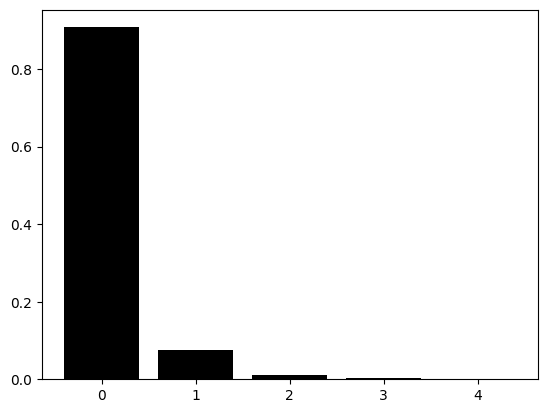

In [33]:
pca = dd.PCA( n_components=X.shape[1] )

principal_components = pca.fit_transform(X)

# plot explained variable
features = range( pca.n_components_ )

plt.bar( features, pca.explained_variance_ratio_, color='black')

# pca component
df_pca = pd.DataFrame( principal_components )

<Axes: xlabel='0', ylabel='1'>

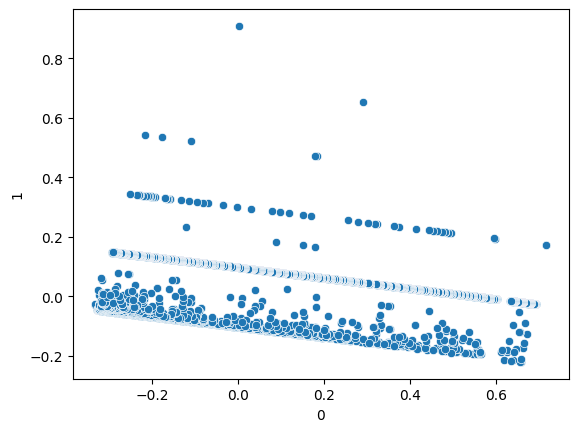

In [34]:
sns.scatterplot( x=0, y=1, data=df_pca)

### 4.3.2. UMAP

/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Axes: xlabel='embedding_x', ylabel='embedding_y'>

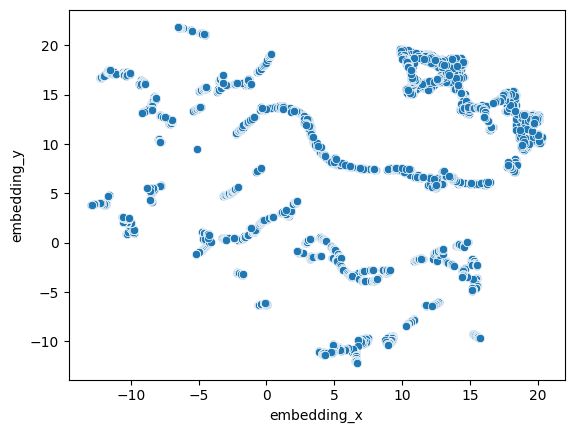

In [35]:
reducer = umap.UMAP( random_state=42 )
embedding = reducer.fit_transform( X )

# embedding
df_umap = pd.DataFrame()
df_umap['embedding_x'] = embedding[:, 0]
df_umap['embedding_y'] = embedding[:, 1]

# plot UMAP
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_umap )

### 4.3.3. t-SNE

<Axes: xlabel='embedding_x', ylabel='embedding_y'>

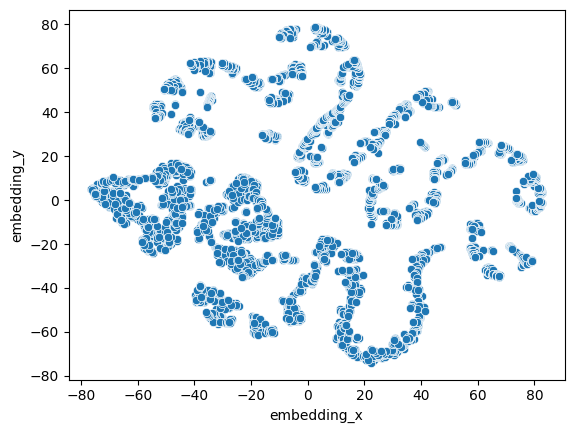

In [36]:
reducer = TSNE( n_components=2, n_jobs=-1, random_state=42 )
embedding = reducer.fit_transform( X )

# embedding
df_tsne = pd.DataFrame()
df_tsne['embedding_x'] = embedding[:, 0]
df_tsne['embedding_y'] = embedding[:, 1]

# plot TSNE
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_tsne )

### 4.3.4. Tree-Based Embedding

In [37]:
# training datasets

X = df43.drop( columns=['gross_revenue'], axis=1)
y = df43['gross_revenue']

# model definition
rf_model = en.RandomForestRegressor( n_estimators=100, random_state=42 )

# model training
rf_model.fit( X, y)

df_leaf = pd.DataFrame( rf_model.apply(X) )

/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


<Axes: xlabel='embedding_x', ylabel='embedding_y'>

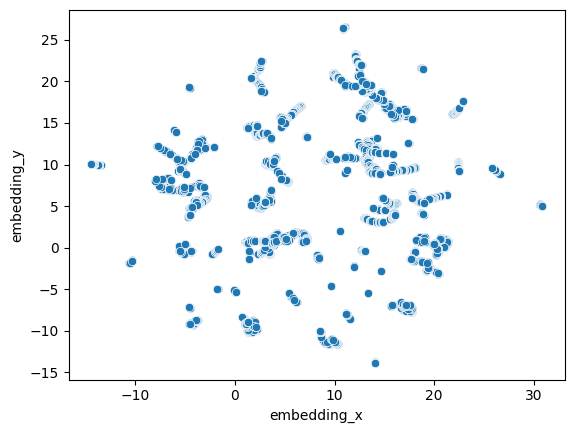

In [38]:
reducer = umap.UMAP( random_state=42 )
embedding = reducer.fit_transform( df_leaf )

# embedding
df_tree = pd.DataFrame()
df_tree['embedding_x'] = embedding[:, 0]
df_tree['embedding_y'] = embedding[:, 1]

# plot UMAP
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_tree)

#  <font color='red'> 5.0. Data Preparation </font>

<span id="papermill-error-cell" style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">Execution using papermill encountered an exception here and stopped:</span>

In [39]:
# Tree-Based Embedding
df5 = df_tree.copy()
df5.to_csv('../src/data/tree_based_embedding.csv')

# UMAP Embedding
#df5 = df_umap.copy()

# TSNE Embedding
#df5 = df_tsne.copy()

OSError: Cannot save file into a non-existent directory: '../src/data'

#  <font color='red'> 7.0. Hyperparameter Fine-Tunning </font>

In [ ]:
X = df5.copy()

In [ ]:
X.head()

In [ ]:
# clusters = [2,3,4,5,6,7]
clusters = np.arange(2, 25, 1)

## 7.1. K-Means 

In [ ]:
kmeans_list = []
for k in clusters:    
    # model definition
    kmeans_model = c.KMeans( n_clusters=k, n_init=100, random_state=42)
    
    # model training
    kmeans_model.fit( X )
    
    # model predict
    labels = kmeans_model.predict( X )
    
    # model preformance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    kmeans_list.append( sil )

In [ ]:
plt.plot( clusters, kmeans_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.2. GMM

In [ ]:
gmm_list = []
for k in clusters:    
    # model definition
    gmm_model = mx.GaussianMixture( n_components=k, n_init=10, random_state=42)
    
    # model training
    gmm_model.fit( X )
    
    # model predict
    labels = gmm_model.predict( X )
    
    # model preformance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    gmm_list.append( sil )

In [ ]:
plt.plot( clusters, gmm_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.3. Hierarquical Clustering

In [ ]:
# model definition and training
hc_model = hc.linkage( X, 'ward')

### 7.3.1. HClustering Silhouette Score

In [ ]:
hc_list = []
for k in clusters: 
    # model definition e training
    hc_model = hc.linkage( X, 'ward')
    
    # model predict
    labels = hc.fcluster( hc_model, k, criterion='maxclust')
    
    # model performance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    hc_list.append( sil )

In [ ]:
plt.plot( clusters, hc_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.5. Results

In [ ]:
# 7.5. Results - Tree Based Embedding

df_results = pd.DataFrame(
    {'Kmeans': kmeans_list,
    'GMM': gmm_list,
    'HC': hc_list
        }
).T

df_results.columns = clusters

In [ ]:
df_results.style.highlight_max(color='lightgreen', axis=1)

#  <font color='red'> 8.0. Model Training </font>

## 8.1. Final Model

In [ ]:
k = 8

# model definition
gmm_model = mx.GaussianMixture( n_components=k, n_init=300, random_state=32 )

# model training
gmm_model.fit( X )

# model predict
labels = gmm_model.predict( X ) 

## 8.2. Cluster Validation

In [ ]:
## WSS (Within-cluster sum of square)
#print( 'WSS value: {}'.format( kmeans.inertia_ ) )

## SS (Silhouette Score)
print( 'SS value: {}'. format( m.silhouette_score( X, labels, metric='euclidean' ) ) )

#  <font color='red'> 9.0. Cluster Analysis </font>

In [ ]:
df9 = X.copy()
df9['cluster'] = labels

## 9.1. Visualization Inspection

In [ ]:
sns.scatterplot( x='embedding_x', y='embedding_y', hue='cluster', data=df9, palette='deep')

## 9.4. Cluster Profile

In [ ]:
df92 = df4[ cols_selected].copy()
df92['cluster'] = labels
df92.head()

In [ ]:
# Number of customer
df_cluster = df92[['customer_id', 'cluster']].groupby( 'cluster' ).count().reset_index()
df_cluster['perc_customer'] = 100 * (df_cluster['customer_id'] / df_cluster['customer_id'].sum())

# Avg Gross revenue
df_avg_gross_revenue = df92[['gross_revenue', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_gross_revenue, how='inner', on='cluster')

# Avg receny days
df_avg_recency_days = df92[['recency_days', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_recency_days, how='inner', on='cluster')

# Avg invoice no
df_avg_invoice_no= df92[['qtde_products', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_invoice_no, how='inner', on='cluster')

# frequency
df_frequency= df92[['frequency', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_frequency, how='inner', on='cluster')

# returns
df_qtde_returns= df92[['qtde_returns', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_qtde_returns, how='inner', on='cluster')


df_cluster.sort_values(by='gross_revenue', ascending=False)

In [ ]:
# 7 Cluster Insiders
# 6 Cluster More Products
# 4 Cluster Spend Money
# 5 Cluster Even More Products
# 3 Cluster Less Days
# 2 Cluster Less 1K
# 1 Cluster Stop Returns
# 0 Cluster More Buy

### Cluster 01: (Candidato a Insider)
    - Número de customers: 468 ( 16% do customers )
    - Faturamento médio: 8836
    - Recência média: 21 dias
    - Média de Produtos Comprados: 424 produtos
    - Frequência de produtos comprados: 0.09 produtos/dia 
    - Receita em média: $ 8.836,13 dólares

### Cluster 02:
    - Número de customers: 31 ( 0.71% do customers )
    - Recência média: 14 dias
    - Compras em média: 53 compras
    - Receita média: $40.543,52 dólares

### Cluster 03:
    - Número de customers: 4.335 ( 99% do customers )
    - Recência média: 92 dias
    - Compras em média: 5 compras
    - Receita média: $1.372,57 dólares

#  <font color='red'> 10.0. Análise Exploratória dos Dados </font>

In [ ]:
df10 = df92.copy()

#  <font color='red'> 11.0. Deploy to Production </font>

In [ ]:
df10.dtypes

In [ ]:
from sqlalchemy import create_engine

In [ ]:
# database connection
conn = create_engine( 'sqlite:///insiders_db.sqlite')

# drop table
query_drop_insiders = """
    DROP TABLE insiders
"""

# create table
query_create_insiders = """
    CREATE TABLE insiders (
        customer_id      INTEGER,
        gross_revenue    REAL,
        recency_days     INTEGER,
        qtde_products    INTEGER,
        frequency        REAL,
        qtde_returns     INTEGER,
        cluster          INTEGER
    )
"""

#conn.execute( query_drop_insiders )
#conn.execute( query_create_insiders )


In [ ]:
# insert data into
df92.to_sql('insiders', con=conn, if_exists='append', index=False)

In [ ]:
## get query
#query_collect = """
#    SELECT * FROM insiders
#"""
#df = pd.read_sql_query( query_collect, conn)
#df.head()